<a href="https://colab.research.google.com/github/jishnujs1990/Sales-Revenue-Vision-Final_Prjct/blob/main/RevenueVision_Final_Project_Completed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RevenueVision — Simple Sales Analysis & Forecasting
**Goal:** Understand sales performance, compare 3 prediction models, and forecast the next 6 months.

Run the cells from top to bottom in **Google Colab or Jupyter**. Only change the CSV path in Step 2.


## 1. Import libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor
import joblib

## 2. Load your sales CSV
Change `file_path` to the CSV location. In Colab you can use `/content/...`.

In [5]:
file_path = "/content/Global_Superstore_Estimated_Dates.csv"
raw = pd.read_csv(file_path)
print("Rows:", len(raw))
display(raw.head())

Rows: 51290


,Category,City,Country,Customer ID,Customer Name,Discount,Market,ji_lu-shu,Order Date,Order ID,...,State,Sub-Category,Year,Market2,weeknum,Original Order Date,Original Ship Date,Dates Are Synthetic,Order Date Method,Ship Date Method
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,US,1,2011-01-08,CA-2011-130813,...,California,Paper,2011,North America,2,2011-01-08,2011-01-12,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,US,1,2011-01-22,CA-2011-148614,...,California,Paper,2011,North America,4,2011-01-22,2011-01-26,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay
2,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-06,CA-2011-118962,...,California,Paper,2011,North America,32,2011-08-06,2011-08-10,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay
3,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-06,CA-2011-118962,...,California,Paper,2011,North America,32,2011-08-06,2011-08-10,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay
4,Office Supplies,Los Angeles,United States,AP-109154,Arthur Prichep,0.0,US,1,2011-10-01,CA-2011-146969,...,California,Paper,2011,North America,40,2011-10-01,2011-10-05,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay


## 3. Clean the data
Remove duplicates, fix the sales and date columns, and keep valid transactions. We **use existing order dates** rather than generating new ones.

In [6]:
df = raw.copy()
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_", regex=False)
df = df.drop_duplicates()
df["sales"] = pd.to_numeric(df["sales"], errors="coerce")
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")
if "profit" in df.columns:
    df["profit"] = pd.to_numeric(df["profit"], errors="coerce")
df = df.dropna(subset=["sales", "order_date"])
df = df[df["sales"] >= 0].copy()
print("Cleaned rows:", len(df))
display(df.head())

Cleaned rows: 51290


,category,city,country,customer_id,customer_name,discount,market,ji_lu-shu,order_date,order_id,...,state,sub-category,year,market2,weeknum,original_order_date,original_ship_date,dates_are_synthetic,order_date_method,ship_date_method
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,US,1,2011-01-08,CA-2011-130813,...,California,Paper,2011,North America,2,2011-01-08,2011-01-12,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,US,1,2011-01-22,CA-2011-148614,...,California,Paper,2011,North America,4,2011-01-22,2011-01-26,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay
2,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-06,CA-2011-118962,...,California,Paper,2011,North America,32,2011-08-06,2011-08-10,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay
3,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-06,CA-2011-118962,...,California,Paper,2011,North America,32,2011-08-06,2011-08-10,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay
4,Office Supplies,Los Angeles,United States,AP-109154,Arthur Prichep,0.0,US,1,2011-10-01,CA-2011-146969,...,California,Paper,2011,North America,40,2011-10-01,2011-10-05,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay


## 4. Business KPIs
Revenue is the sum of the `sales` column; do not multiply it by quantity again.

In [7]:
print(f"Total Revenue: {df['sales'].sum():,.2f}")
print(f"Average Sales per Row: {df['sales'].mean():,.2f}")
if "profit" in df.columns:
    print(f"Total Profit: {df['profit'].sum():,.2f}")
    print(f"Profit Margin: {100 * df['profit'].sum() / df['sales'].sum():.1f}%" if df['sales'].sum() else "Profit Margin: N/A")

Total Revenue: 12,642,905.00
Average Sales per Row: 246.50
Total Profit: 1,467,457.29
Profit Margin: 11.6%


## 5. Explore sales visually
These charts show the monthly trend and the best-performing categories/regions when available.

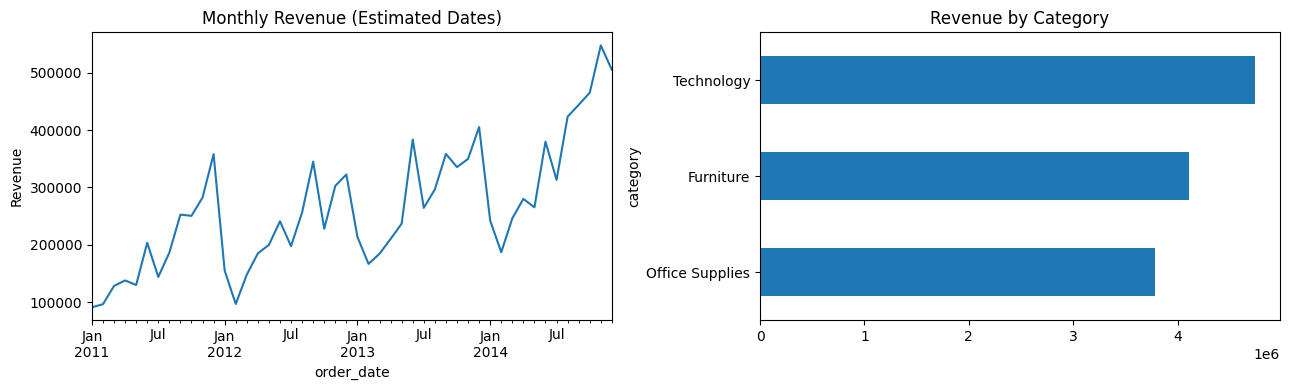

In [8]:
monthly = df.set_index("order_date")["sales"].resample("MS").sum()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
monthly.plot(ax=axes[0], title="Monthly Revenue (Estimated Dates)")
axes[0].set_ylabel("Revenue")
if "category" in df.columns:
    df.groupby("category")["sales"].sum().sort_values().plot.barh(ax=axes[1], title="Revenue by Category")
elif "region" in df.columns:
    df.groupby("region")["sales"].sum().sort_values().plot.barh(ax=axes[1], title="Revenue by Region")
else:
    axes[1].axis("off")
plt.tight_layout()
plt.show()

## 6. Prepare data for machine learning
We use the previous **3 months of revenue** to predict the next month. `shift()` prevents the model from seeing the current month in advance.

In [9]:
data = pd.DataFrame({"revenue": monthly})
for lag in [1, 2, 3]:
    data[f"lag_{lag}"] = data["revenue"].shift(lag)
data["month_number"] = data.index.month
model_data = data.dropna().copy()
features = ["lag_1", "lag_2", "lag_3", "month_number"]
if len(model_data) < 12:
    raise ValueError("At least 15 months of data are recommended for this example.")
# Reserve the last 20% of months for testing (at least 3 months).
test_size = max(3, int(len(model_data) * 0.2))
train, test = model_data.iloc[:-test_size], model_data.iloc[-test_size:]
X_train, y_train = train[features], train["revenue"]
X_test, y_test = test[features], test["revenue"]
print("Train months:", len(train), "| Test months:", len(test))

Train months: 36 | Test months: 9


## 7. Train and compare 3 models
**MAE** is the average size of prediction errors. **RMSE** penalizes large errors more. Lower is better. We compare models on the final held-out months; no complicated tuning is necessary for this learning project.

In [10]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, max_depth=3, learning_rate=0.1,
                             objective="reg:squarederror", random_state=42)
}
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    predicted = model.predict(X_test)
    results.append({"Model": name,
                    "MAE": mean_absolute_error(y_test, predicted),
                    "RMSE": np.sqrt(mean_squared_error(y_test, predicted))})
comparison = pd.DataFrame(results).sort_values("MAE").reset_index(drop=True)
display(comparison)
best_name = comparison.loc[0, "Model"]
print("Lowest test MAE:", best_name)
# Note: Choosing on the test set makes this an exploratory comparison, not an unbiased final evaluation.

,Model,MAE,RMSE
0,Linear Regression,84784.753692,95375.973719
1,XGBoost,87676.750000,96505.649658
2,Random Forest,95544.585556,109862.289890


Lowest test MAE: Linear Regression


## 8. Check actual vs predicted revenue
This plot shows predictions for historical months, not future months.

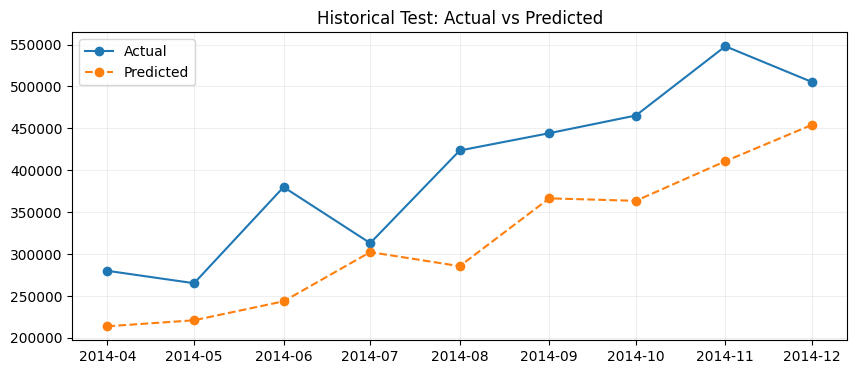

,month,actual,predicted
0,2014-04-01,280075,213911.041323
1,2014-05-01,265271,221074.431330
2,2014-06-01,379996,243690.551703
3,2014-07-01,313115,302393.103851
4,2014-08-01,423620,285637.064976
5,2014-09-01,444267,366530.785616
6,2014-10-01,465359,363571.595297
7,2014-11-01,547950,410868.749498
8,2014-12-01,505324,454236.893179


In [11]:
best_model = models[best_name]
test_predictions = pd.DataFrame({"month": test.index, "actual": y_test.values,
                                 "predicted": best_model.predict(X_test)})
plt.figure(figsize=(10, 4))
plt.plot(test_predictions["month"], test_predictions["actual"], "o-", label="Actual")
plt.plot(test_predictions["month"], test_predictions["predicted"], "o--", label="Predicted")
plt.title("Historical Test: Actual vs Predicted")
plt.legend(); plt.grid(alpha=0.2); plt.show()
display(test_predictions)

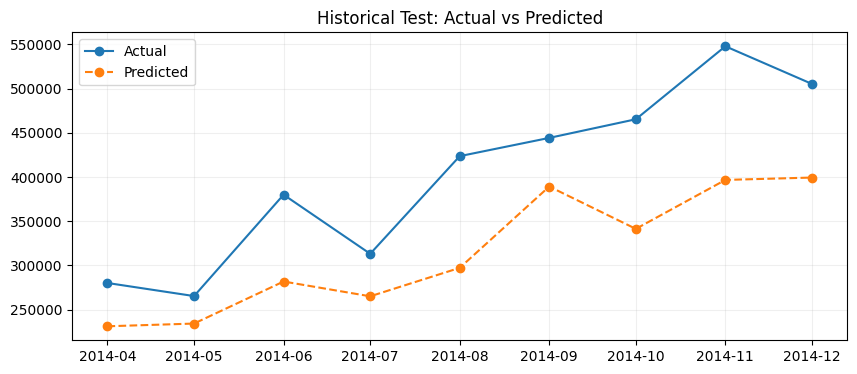

,month,actual,predicted
0,2014-04-01,280075,231087.875000
1,2014-05-01,265271,234164.296875
2,2014-06-01,379996,281746.968750
3,2014-07-01,313115,265011.468750
4,2014-08-01,423620,297212.843750
5,2014-09-01,444267,389231.500000
6,2014-10-01,465359,341328.843750
7,2014-11-01,547950,396713.437500
8,2014-12-01,505324,399389.000000


In [12]:
best_model = models['XGBoost']
test_predictions = pd.DataFrame({"month": test.index, "actual": y_test.values,
                                 "predicted": best_model.predict(X_test)})
plt.figure(figsize=(10, 4))
plt.plot(test_predictions["month"], test_predictions["actual"], "o-", label="Actual")
plt.plot(test_predictions["month"], test_predictions["predicted"], "o--", label="Predicted")
plt.title("Historical Test: Actual vs Predicted")
plt.legend(); plt.grid(alpha=0.2); plt.show()
display(test_predictions)

## 9. Forecast the next 6 months
Train the chosen model again on all available months, then predict one future month at a time. Each new prediction becomes an input for the next month, so uncertainty increases further into the future.

,month,forecast_revenue
0,2015-01-01,484523.28125
1,2015-02-01,486500.78125
2,2015-03-01,487649.18750
3,2015-04-01,487649.18750
4,2015-05-01,489273.18750
5,2015-06-01,491802.06250


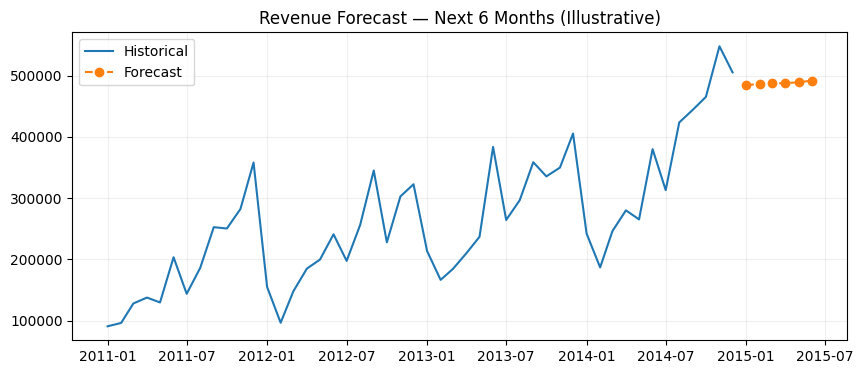

In [14]:
best_model.fit(model_data[features], model_data["revenue"])
history = list(monthly.values.astype(float))
next_months = pd.date_range(monthly.index[-1] + pd.offsets.MonthBegin(1), periods=6, freq="MS")
future_values = []
for month in next_months:
    row = pd.DataFrame([{"lag_1": history[-1], "lag_2": history[-2],
                         "lag_3": history[-3], "month_number": month.month}])
    forecast = max(0, float(best_model.predict(row[features])[0]))
    future_values.append(forecast)
    history.append(forecast)
forecast_df = pd.DataFrame({"month": next_months, "forecast_revenue": future_values})
display(forecast_df)
plt.figure(figsize=(10, 4))
plt.plot(monthly.index, monthly.values, label="Historical")
plt.plot(forecast_df["month"], forecast_df["forecast_revenue"], "o--", label="Forecast")
plt.title("Revenue Forecast — Next 6 Months (Illustrative)")
plt.legend(); plt.grid(alpha=0.2); plt.show()

,month,forecast_revenue
0,2015-01-01,484523.28125
1,2015-02-01,486500.78125
2,2015-03-01,487649.18750
3,2015-04-01,487649.18750
4,2015-05-01,489273.18750
5,2015-06-01,491802.06250


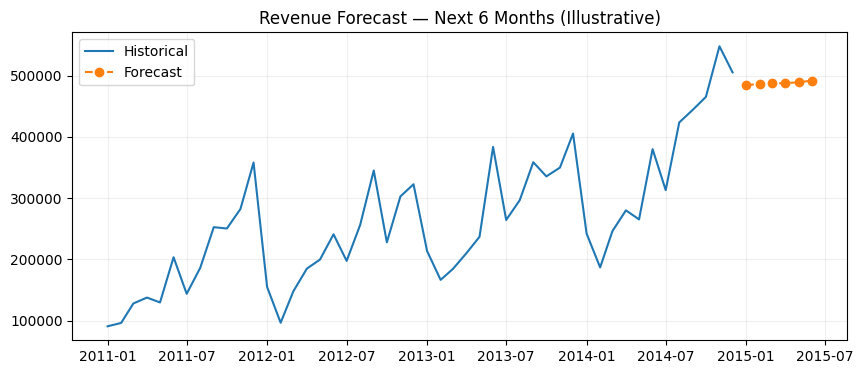

In [18]:
best_model1 = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)
best_model1.fit(model_data[features], model_data["revenue"])
history = list(monthly.values.astype(float))
next_months = pd.date_range(monthly.index[-1] + pd.offsets.MonthBegin(1), periods=6, freq="MS")
future_values = []
for month in next_months:
    row = pd.DataFrame([{"lag_1": history[-1], "lag_2": history[-2],
                         "lag_3": history[-3], "month_number": month.month}])
    forecast = max(0, float(best_model1.predict(row[features])[0]))
    future_values.append(forecast)
    history.append(forecast)
forecast_df = pd.DataFrame({"month": next_months, "forecast_revenue": future_values})
display(forecast_df)
plt.figure(figsize=(10, 4))
plt.plot(monthly.index, monthly.values, label="Historical")
plt.plot(forecast_df["month"], forecast_df["forecast_revenue"], "o--", label="Forecast")
plt.title("Revenue Forecast — Next 6 Months (Illustrative)")
plt.legend(); plt.grid(alpha=0.2); plt.show()

## 10. Business insights
Simple, automatically calculated findings you can explain in your project presentation.

In [19]:
print("1. Total sales revenue:", round(df["sales"].sum(), 2))
print("2. Highest estimated monthly revenue:", monthly.idxmax().strftime("%Y-%m"),
      "=", round(monthly.max(), 2))
if "category" in df.columns:
    print("3. Top category:", df.groupby("category")["sales"].sum().idxmax())
if "region" in df.columns:
    print("4. Top region:", df.groupby("region")["sales"].sum().idxmax())
print("5. Best exploratory model:", best_name)
print("6. Forecast total for next 6 months:", round(forecast_df["forecast_revenue"].sum(), 2))

1. Total sales revenue: 12642905
2. Highest estimated monthly revenue: 2014-11 = 547950
3. Top category: Technology
4. Top region: Central
5. Best exploratory model: Linear Regression
6. Forecast total for next 6 months: 2927397.69


## 11. Save results
These files can be used in a report or Power BI. The saved model should only be loaded from trusted files.

In [20]:
df.to_csv("RevenueVision_Cleaned_Data.csv", index=False)
comparison.to_csv("RevenueVision_Model_Comparison.csv", index=False)
test_predictions.to_csv("RevenueVision_Test_Predictions.csv", index=False)
forecast_df.to_csv("RevenueVision_Future_Forecast.csv", index=False)
joblib.dump(best_model, "RevenueVision_Best_Model.joblib")
print("Saved cleaned data, model comparison, test predictions, future forecast, and model.")

Saved cleaned data, model comparison, test predictions, future forecast, and model.


## 12. How to explain this project
1. **Problem:** Understand past sales and estimate upcoming revenue.
2. **Cleaning:** Remove duplicates, invalid dates, and invalid sales.
3. **Analysis:** Show revenue, profit, category performance, and monthly trends.
4. **Models:** Compare Linear Regression, Random Forest, and XGBoost using MAE/RMSE.
5. **Forecast:** Use the selected model to estimate the next 6 months.
6. **Limitations:** Dates were estimated in the source CSV. Results depend on those assumptions. The model is selected using the held-out test period, so the reported test score is exploratory rather than a fully independent final estimate.

**Intentionally omitted:** SQL queries, clustering, extensive feature engineering, complex hyperparameter tuning, FastAPI, and GitHub setup. Those can be added later if your mentor requires them.